# Lab 12 — The depot in MuJoCo

**Book sections:** [Appendix A](../../book/docs/appendix/mujoco.md), [9.1](../../book/docs/chapters/09-training/stages.md)
(co-training), [9.4](../../book/docs/chapters/09-training/finetuning.md) (fine-tuning).

**Goal.** Move the depot task from the flat 2-D world into a physics simulator. You will read the MJCF model,
watch the velocity actuators lag behind commands, render the overhead and onboard cameras, recover 3-D points
from pixels with the camera intrinsics, and then measure the **sim-to-sim gap**: how a VLA trained in the 2-D
world (Lab 11) does in MuJoCo, and how much fine-tuning and co-training on a small amount of MuJoCo data recover —
without forgetting the original world.

**Runtime:** ≈20 min with a GPU. **Downloads:** none. **GPU:** ≈1.5 GB. **Seed:** 0.
**Reads** `data/checkpoints/toy_vla_mse.pt` from Lab 11 and `tiny_clip.pt` from Lab 07.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import mujoco
import numpy as np
import torch

from vlacourse.clip import TinyCLIP
from vlacourse.data import scenes
from vlacourse.depot_env import INSTR_VOCAB, DepotNav, collect, evaluate, pad_instructions
from vlacourse.mujoco_depot import CTRL_DT, SIDE, SIM_DT, MujocoDepotNav, depot_xml, to_world
from vlacourse.seed import device, set_seed
from vlacourse.vision import to_tensor
from vlacourse.vla import TinyVLA

set_seed(0)
dev = device()
CK = Path("../../data/checkpoints")
print("MuJoCo", mujoco.__version__, "| device", dev, "| Lab 11 checkpoint:", (CK / "toy_vla_mse.pt").exists())

MuJoCo 3.15.0 | device cuda | Lab 11 checkpoint: True


## 1. The model: MJCF
`depot_xml(scene)` writes the MJCF for one scene: a floor, an overhead camera, one body per object (visual only:
`contype=0`, so the robot drives over footprints), and the robot — a 6 kg cylinder on two slide joints with
velocity actuators. Compile it and look at what MuJoCo built.

In [2]:
env = MujocoDepotNav(res=64)
obs = env.reset(seed=10)
xml = depot_xml(env.scene, env.p)
print("\n".join(l for l in xml.splitlines() if "robot" in l or "actuator" in l or "velocity" in l or "camera" in l))
m = env.model
print(f"\nbodies {m.nbody}, geoms {m.ngeom}, joints {m.njnt}, actuators {m.nu}, cameras {m.ncam}, "
      f"timestep {m.opt.timestep * 1000:.0f} ms, control period {CTRL_DT * 1000:.0f} ms "
      f"= {round(CTRL_DT / SIM_DT)} physics steps")
print("instruction:", obs["instruction"])

    <camera name="top" pos="0 0 4.8284" xyaxes="1 0 0 0 1 0" fovy="45"/>
    <body name="robot" pos="-1.5644039917778296 0.0333124448260913 .08">
      <camera name="onboard" pos="0 0 .3" xyaxes="0 -1 0 0 0 1" fovy="70"/>
  <actuator>
    <velocity name="vx" joint="x" kv="60" ctrlrange="-1.6 1.6"/>
    <velocity name="vy" joint="y" kv="60" ctrlrange="-1.6 1.6"/>
  </actuator>

bodies 4, geoms 9, joints 2, actuators 2, cameras 2, timestep 5 ms, control period 100 ms = 20 physics steps
instruction: go to the blue cone


## 2. Actuators have dynamics
A velocity actuator applies force $k_v(u-\dot q)$. With mass $m=6$ kg and $k_v=60$ the velocity approaches the
command with time constant $\tau\approx m/(k_v+b)\approx0.1$ s — one control period. In the 2-D world a command
took effect instantly. Command full speed along $x$ for 0.5 s, then zero.

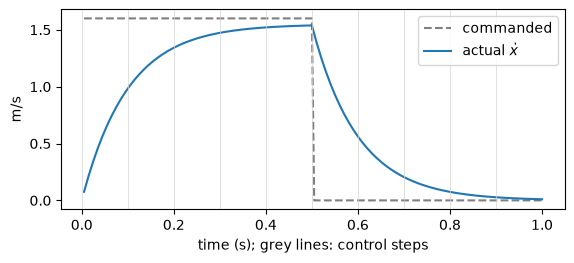

63% rise time: 110 ms (theory m / (k_v + damping) = 97 ms)


In [3]:
env.reset(seed=10)
d = env.data
v, t = [], []
for k in range(200):
    d.ctrl[:] = [1.6, 0.0] if k < 100 else [0.0, 0.0]
    mujoco.mj_step(env.model, d)
    v.append(d.qvel[0]); t.append((k + 1) * SIM_DT)
v, t = np.array(v), np.array(t)
tau = t[np.argmax(v > 1.6 * (1 - np.exp(-1)))]
plt.figure(figsize=(6.5, 2.6))
plt.plot(t, np.where(t <= 0.5, 1.6, 0), "--", color="gray", label="commanded")
plt.plot(t, v, label="actual $\\dot x$")
for c in np.arange(0, 1.0, CTRL_DT):
    plt.axvline(c, color="lightgray", lw=0.5)
plt.xlabel("time (s); grey lines: control steps"); plt.ylabel("m/s"); plt.legend(); plt.show()
print(f"63% rise time: {tau * 1000:.0f} ms (theory m / (k_v + damping) = {6 / 62 * 1000:.0f} ms)")

## 3. Cameras: rendering, depth and intrinsics
Render the overhead camera (the policy's observation) and the robot's onboard camera, plus depth.

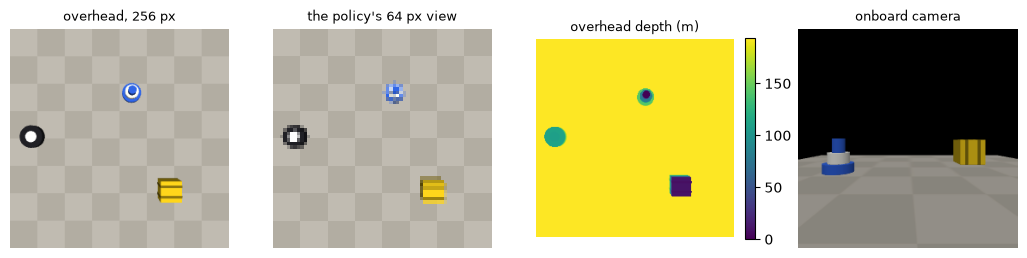

In [4]:
env.reset(seed=10)
R = mujoco.Renderer(env.model, 256, 256)
R.update_scene(env.data, camera="top"); top = R.render().copy()
R.enable_depth_rendering(); R.update_scene(env.data, camera="top"); depth = R.render().copy(); R.disable_depth_rendering()
R.update_scene(env.data, camera="onboard"); onboard = R.render().copy()
fig, axs = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, im, ttl in [(axs[0], top, "overhead, 256 px"), (axs[1], obs["image"], "the policy's 64 px view"),
                    (axs[2], depth, "overhead depth (m)"), (axs[3], onboard, "onboard camera")]:
    h = ax.imshow(im, cmap="viridis" if im.ndim == 2 else None); ax.set_title(ttl, fontsize=9); ax.axis("off")
plt.colorbar(h, ax=axs[2], fraction=0.046); plt.show()

**Deprojection.** For the overhead camera, $f=(H/2)/\tan(\mathrm{fovy}/2)$ and a pixel $(u,v)$ with depth $z$
(distance along the optical axis) is the camera-frame point $\big((u+\tfrac12-\tfrac W2)\,z/f,\ (\tfrac H2-v-\tfrac12)\,z/f,\ -z\big)$.
The camera's axes are aligned with the world's, so adding the camera position gives world coordinates.
Deproject the pixel at the centre of each object and compare with MuJoCo's own body positions.

In [5]:
H = W = 256
fovy = env.model.cam_fovy[0]
f = (H / 2) / np.tan(np.radians(fovy) / 2)
cam = env.data.cam_xpos[0]
print(f"f = {f:.1f} px, camera at {np.round(cam, 3)} m")
for i, o in enumerate(env.scene.objects):
    u, v_ = int(o.x * W), int(o.y * H)                # where the object's footprint centre appears
    z = depth[v_, u]
    p = cam + np.array([(u + 0.5 - W / 2) * z / f, (H / 2 - v_ - 0.5) * z / f, -z])
    body = env.data.body(f"obj{i}").xpos
    ray = body[:2] * (cam[2] - p[2]) / cam[2]           # where the ray through the footprint pixel is at height p_z
    print(f"{o.color:7s} {o.kind:8s} pixel ({u:3d},{v_:3d}) depth {z:.2f} m -> world {np.round(p, 3)}; "
          f"body origin {np.round(body[:2], 3)}; same ray at that height {np.round(ray, 3)}")

f = 309.0 px, camera at [0.    0.    4.828] m
blue    cone     pixel (141, 75) depth 4.46 m -> world [0.195 0.758 0.369]; body origin [0.219 0.823]; same ray at that height [0.202 0.76 ]
yellow  crate    pixel (184,185) depth 4.46 m -> world [ 0.816 -0.831  0.365]; body origin [ 0.877 -0.906]; same ray at that height [ 0.811 -0.838]


The deprojected point is not the body origin: the ray through the pixel where the object's *footprint* centre
would appear first hits the object's **top surface**, about 0.37 m up, where it is closer to the optical axis by
the factor $(4.83-0.37)/4.83pprox0.92$. Scaling the origin by that factor reproduces the measurement to within a
pixel (4 m / 256 px ≈ 1.6 cm). Depth turns a pixel into the 3-D point the camera actually sees — the step that makes
a VLM's pixel-space grounding (book 4.4, 5.4) usable by a controller — and perspective is exactly what a flat
2-D image hides.

## 4. The visual gap
The same scene in both worlds. Objects now have height, perspective and shading; the floor has a texture.

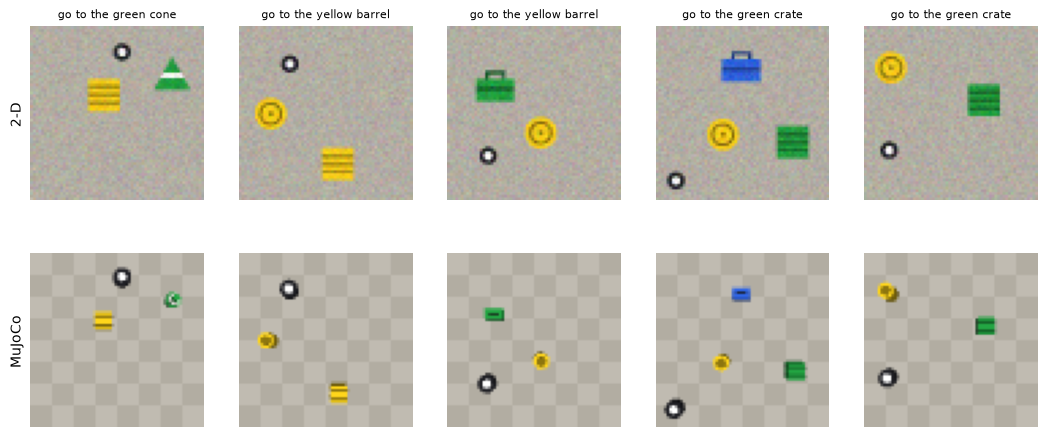

mean |pixel difference| between the two renderings: 14.9 / 255


In [6]:
flat, sim = DepotNav(), MujocoDepotNav()
fig, axs = plt.subplots(2, 5, figsize=(13, 5.4))
for k in range(5):
    a, b = flat.reset(seed=100 + k), sim.reset(seed=100 + k)
    axs[0, k].imshow(a["image"]); axs[1, k].imshow(b["image"])
    axs[0, k].set_title(a["instruction"], fontsize=8)
    for r in (0, 1):
        axs[r, k].axis("off")
axs[0, 0].text(-8, 32, "2-D", rotation=90, va="center"); axs[1, 0].text(-8, 32, "MuJoCo", rotation=90, va="center")
plt.show()
print(f"mean |pixel difference| between the two renderings: "
      f"{np.mean([np.abs(flat.reset(seed=s)['image'].astype(int) - sim.reset(seed=s)['image'].astype(int)).mean() for s in range(50)]):.1f} / 255")

And the expert, which reads the true state, still solves the task despite the actuator lag:

In [7]:
ok = 0
for s in range(50):
    sim.reset(seed=500 + s); done = False
    while not done:
        _, done, succ = sim.step(sim.expert_action())
    ok += succ
print(f"expert success in MuJoCo: {ok}/50")

expert success in MuJoCo: 50/50


## 5. The sim-to-sim gap
Load the Lab 11 policy (regression head, frozen tiny-CLIP vision encoder, trained on 2-D demonstrations) and
evaluate it closed-loop in both worlds. MuJoCo episodes run one at a time (the environments share one renderer).

In [8]:
def load_vla(path=None):
    clip = TinyCLIP(len(scenes.VOCAB))
    if (CK / "tiny_clip.pt").exists():
        clip.load_state_dict(torch.load(CK / "tiny_clip.pt", map_location="cpu"))
    m = TinyVLA(len(INSTR_VOCAB), head="mse", vision=clip.image_encoder).to(dev)
    if path is not None:
        m.load_state_dict(torch.load(path, map_location=dev))
    return m.eval()


def policy_of(m):
    def pol(img, ins, st):
        with torch.no_grad():
            return m.act(to_tensor(img).to(dev), torch.as_tensor(ins).to(dev), torch.as_tensor(st).to(dev)).cpu().numpy()
    return pol


def both_worlds(m, label, n2d=200, nsim=100):
    t0 = time.time()
    s2 = evaluate(policy_of(m), n2d, execute=4)["success"].mean()
    s3 = evaluate(policy_of(m), nsim, execute=4, env_factory=MujocoDepotNav, parallel=1)["success"].mean()
    print(f"{label:42s} 2-D {s2:.2f}   MuJoCo {s3:.2f}   ({time.time() - t0:.0f} s)")
    return s2, s3


results = {}
base = load_vla(CK / "toy_vla_mse.pt")
results["trained in 2-D (Lab 11)"] = both_worlds(base, "trained in 2-D (Lab 11)")

trained in 2-D (Lab 11)                    2-D 0.84   MuJoCo 0.46   (17 s)


## 6. Collecting MuJoCo demonstrations
1500 episodes (three tasks per scene) — an eighth of Lab 11's data, as if MuJoCo (or a real robot) were the
expensive world.

In [9]:
t0 = time.time()
Dm = collect(1500, seed=7, chunk=8, env=MujocoDepotNav(), tasks_per_scene=3)
D2 = collect(6000, seed=1, chunk=8, tasks_per_scene=3)
print(f"MuJoCo: {len(Dm['action'])} steps; 2-D: {len(D2['action'])} steps ({time.time() - t0:.0f} s)")


def tensors(D):
    return (torch.as_tensor(D["image"]), torch.as_tensor(pad_instructions(D["instruction"], 5)),
            torch.as_tensor(D["state"]), torch.as_tensor(D["chunk"]))


SIMDATA, FLATDATA = tensors(Dm), tensors(D2)

MuJoCo: 19669 steps; 2-D: 69505 steps (165 s)


## 7. Three ways to use the MuJoCo data
* **from scratch**: train only on the 1500 MuJoCo episodes;
* **fine-tune**: start from the 2-D policy, train only on MuJoCo data;
* **co-train**: start from the 2-D policy, every batch half MuJoCo, half 2-D (book 9.1).

Same number of steps and learning rate for all three; the vision encoder stays frozen as in Lab 11.

In [10]:
def train(m, steps=2500, mix=0.0, lr=3e-4, seed=0):
    set_seed(seed)
    for p in m.vision.parameters():
        p.requires_grad = False
    params = [p for p in m.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.05)
    m.train()
    n_flat = int(128 * mix)
    for _ in range(steps):
        parts = []
        for data, n in [(SIMDATA, 128 - n_flat), (FLATDATA, n_flat)]:
            if n:
                j = torch.randint(0, len(data[0]), (n,))
                parts.append([t[j] for t in data])
        X, I, S, A = [torch.cat(z) for z in zip(*parts)]
        loss = m.loss(to_tensor(X).to(dev), I.to(dev), S.to(dev), A.to(dev))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step()
    return m.eval()


for label, path, mix in [("from scratch on MuJoCo data", None, 0.0),
                         ("2-D policy fine-tuned on MuJoCo data", CK / "toy_vla_mse.pt", 0.0),
                         ("2-D policy co-trained (50% MuJoCo, 50% 2-D)", CK / "toy_vla_mse.pt", 0.5)]:
    results[label] = both_worlds(train(load_vla(path), mix=mix), label)

from scratch on MuJoCo data                2-D 0.10   MuJoCo 0.14   (25 s)


2-D policy fine-tuned on MuJoCo data       2-D 0.78   MuJoCo 0.86   (14 s)


2-D policy co-trained (50% MuJoCo, 50% 2-D) 2-D 0.88   MuJoCo 0.83   (14 s)


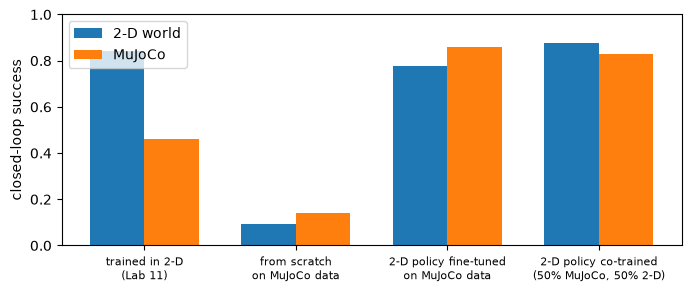

In [11]:
labels = list(results)
x = np.arange(len(labels))
plt.figure(figsize=(8, 3))
plt.bar(x - 0.18, [results[k][0] for k in labels], 0.36, label="2-D world")
plt.bar(x + 0.18, [results[k][1] for k in labels], 0.36, label="MuJoCo")
plt.xticks(x, [k.replace(" (", "\n(").replace(" on ", "\non ") for k in labels], fontsize=8)
plt.ylabel("closed-loop success"); plt.ylim(0, 1); plt.legend(); plt.show()

Read the four pairs of bars as the life cycle of a policy moved to a new embodiment or simulator (book 9.1, 9.4):
a policy trained in one world loses much of its success in the other, even though the task, instructions and
expert are identical; a small amount of target-world data recovers most of it, far more efficiently when starting
from the pretrained policy than from scratch; and fine-tuning only on the new world tends to erode the old one,
which co-training preserves at a small cost. Sim-to-real transfer has the same structure, with a larger gap.

## Exercises
1. **Domain randomisation.** Randomise lighting (`m.light_diffuse`), floor colour and object colours slightly
   while collecting 2-D-equivalent MuJoCo data. Does a policy trained on randomised MuJoCo data transfer better to
   the unrandomised one, and to the 2-D world?
2. **Actuator gap.** Lower `kv` to 15 (τ ≈ 0.4 s) and evaluate the fine-tuned policy. Which execution horizon
   works best now, and why (book 8.6)?
3. **Onboard camera.** Train on the onboard camera instead of the overhead one. Which instructions become hard?
4. **Data efficiency.** Repeat §7 with 250, 500 and 3000 MuJoCo episodes and plot success against data for
   "from scratch" and "fine-tune".
5. **Grounding to 3-D.** Use the deprojection of §3 to turn a pixel chosen by the tiny VLM of Lab 08 into a
   3-D goal, and drive the robot there with a P-controller instead of a learned policy.